# Correcting last round's report from raw data: item 0a, re-derived from the program rows

**Artifact:** `art_7KO_qYLRZxXL`, an evaluation (the iteration-10 "S0 record repair"). It runs on CPU only: no model calls, USD 0.

### The question behind the numbers
The research run asks whether banning names in a prompt makes an LLM produce a genuinely *different* solution.

**The setup.** Models were asked to implement a grid path-search function while being told not to use the k most common algorithms. At k = 5, the banned names are BFS, DFS, IDDFS, A* and greedy best-first. A program can comply in two senses:
- **lexically:** it never names a banned algorithm (`lexical_L1`);
- **mechanistically:** what it actually does is not a banned search.

**The measure.** The **rename gap** is lexical minus mechanistic compliance on the same programs. It counts the programs that dodge the names but re-implement a banned search under a new name.

**The bars.** The preregistered ("committed") bars for a model are:
- a k = 5 gap ≥ 0.4;
- on held-out prompt templates, a gap ≥ 0.4 with a 95% lower bound > 0.

### What the artifact does
A blocking review of the iteration-9 report questioned items 0a-0j. The artifact recomputes every one of them from the raw rows of three dependency artifacts and writes 27 verbatim old→new corrections into the report. It backs them with an apply test, a lint, GRIM checks and two independent standard-library audits.

Its `eval.py` is a stage CLI (`uv run eval.py setup|controls|0a|…|0j|edits|figures|ledger|audit|spotcheck|readme|out|all`) that dispatches to modules in `src/`.

### What this notebook runs
Item **0a** asks: *does the conclusion survive every way of reading "mechanistic compliance"?* There are six readings:
- the runtime label (primary);
- the runtime fine classes;
- a tracer, in coarse and fine order classes;
- one reader's hand reads;
- a sensitivity that counts unit-weight Dijkstra / IDA* / JPS as compliant.

The notebook runs two pieces of the artifact's code:
1. **Stage 0a.** The code of `src/s_rename.py`, with the vendored iteration-9 statistics, applied to the two Qwen3-32B k = 5 cells: committed templates `A_k5` and held-out templates `A_k5_ho`, 100 programs with 62 hand reads. It produces Table 431b with paired Newcombe 95% CIs, exact McNemar tests and the committed bars, plus the item's positive control against the stored iteration-9 counts.
2. **Stage `spotcheck`.** The independent standard-library re-derivation in `audit/spotcheck.py`, together with its McNemar placebo.

The other stages need about 100 MB of rows from the three dependencies and the 1.5 MB report, so they are not part of this demo.

### Published result to reproduce
For Qwen3-32B at k = 5, mechanistic compliance by reading:

| reading | mechanistic compliance | gap |
|---|---|---|
| runtime label | 10/46 = 0.22 | 0.67 |
| hand reads | 27/46 = 0.59 | 0.30 |
| tracer | 0.67 | 0.22 |
| fine tracer | 0.74 | 0.15 |

On held-out templates, the hand-read gap is 0.396 < 0.4. **So Qwen3-32B meets both committed bars only under the runtime label.**

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (the artifact pins loguru 0.7.3)
_pip('loguru==0.7.3')

# numpy, matplotlib -- pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- eval.py ----
import sys
import time
from pathlib import Path

from loguru import logger

# ---- src/io_util.py, src/rows.py, src/s_rename.py ----
import csv
import json
from collections import Counter
from datetime import datetime, timezone
from functools import lru_cache
from typing import Any, Callable, Iterable

# ---- vendored iteration-9 code (common.py, stats_v9.py, analysis_v9.py) and audit/spotcheck.py ----
import math
import random

import numpy as np

# ---- notebook additions ----
from types import SimpleNamespace      # stand-ins for the imported module objects (vend.A, vend.S, rows as RW)
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-10/evaluation-9/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["description"])
print(f"\n{len(data['examples'])} program rows:", dict(Counter(r["cell"] for r in data["examples"])),
      f"| hand reads nested: {sum(1 for r in data['examples'] if r['manual_read'])}")
print("other blocks:", [k for k in data if k not in ("description", "examples")])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Qwen3-32B k = 5 exhaustion cells (committed templates A_k5, held-out templates A_k5_ho) of the iteration-9 rename experiment: each example is one generated path-search program with its lexical label, runtime label, tracer classes (coarse and fine) and, where a program was read by hand, the hand read. Input of item 0a of the iteration-10 S0 record repair.

100 program rows: {'A_k5': 50, 'A_k5_ho': 50} | hand reads nested: 62
other blocks: ['source', 'stored_n3', 'stored_n3_tracer', 'expected']


## Configuration

`MODELS`, `CELL_IDS` and `CELL_KEYS` describe what the demo data holds. The original loops over both models (Qwen3-32B and Qwen3-14B) and over six cells: k = 1..5 plus the held-out cell.

The tunable parameters:
- **`N_ROWS_PER_CELL`:** how many programs of each cell are used, taken in file order. The original uses all 50, and the published numbers are reproduced exactly only at 50. Fewer rows run the same code on a subset. Below 2 rows, the original code stops: it assumes each reading has at least one traceable program.
- **`N_PLACEBO_DRAWS` / `PLACEBO_SEED`:** the spot-check's McNemar placebo (original: 200 draws, seed 20261025).
- **`OUT_DIR`:** where the stage writes `results/s0a.json`, `tables/*.csv`, `logs/run.log` and `STATUS.md`. The original writes these into its own folder.

Even at the original values, the whole computation takes well under a second.

In [5]:
# ---- demo scope: what the demo data holds (the original loops over both models and all six cells) ----
MODELS = ("q32",)                  # original: ("q32", "q14")  -- Qwen3-32B only
CELL_IDS = ("A_k5", "A_k5_ho")     # original: ("A_k5", "A_k5_ho", "E_k5", "E_k5_ho")
CELL_KEYS = ("5", "ho")            # original: ("1", "2", "3", "4", "5", "ho")  -- k = 5, committed and held-out templates

# ---- tunable parameters ----
N_ROWS_PER_CELL = 50               # programs used per cell, in file order (original: all 50; the published values need 50)
N_PLACEBO_DRAWS = 200              # spot-check McNemar placebo draws (original: 200)
PLACEBO_SEED = 20261025            # spot-check placebo seed (original: 20261025)
OUT_DIR = Path("s0_demo_out")      # where the stage writes results/, tables/, logs/, STATUS.md (original: the artifact folder)

## Vendored statistics (iteration-9 `common.py` / `stats_v9.py`, unmodified)

The artifact does not re-implement its statistics. It calls the exact functions the iteration-9 record used, which are copied unmodified into `vendor/` with SHA-256 sums:
- **`wilson_ci`:** the Wilson score interval for a proportion.
- **`newcombe_paired`:** Newcombe's (1998b) method-10 interval for a difference of **paired** proportions. The gap is paired because lexical and mechanistic compliance are measured on the same programs. The 2×2 cells are: a = compliant both ways, b = lexically only (a *covert rename*), c = mechanistically only, d = neither.
- **`mcnemar_exact`:** the exact McNemar test on the discordant counts b and c.
- **`newcombe_diff` / `unpaired_diff`:** the unpaired version, used by item 0c.

In the original, these arrive through `from vend import A, S`. Here `S` is a `SimpleNamespace` holding the same functions, so the stage code below stays verbatim. The printed line reproduces two textbook checks from `stats_v9.self_test`: a Newcombe Table III row, (36, 12, 2, 0) → (0.0569, 0.3404), and an exact McNemar value, b = 1, c = 7 → p = 0.0703.

In [6]:
# ---- vendor/art_8nXdw3_lDAll/common.py (unmodified excerpt) ----
Z95 = 1.959963984540054


def wilson_ci(k: int, n: int, z: float = Z95) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


def newcombe_diff(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float, float]:
    """Newcombe hybrid-score 95% interval for p1 - p2 (method 10)."""
    if n1 <= 0 or n2 <= 0:
        return (float("nan"), float("nan"), float("nan"))
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson_ci(k1, n1)
    l2, u2 = wilson_ci(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return (d, lo, hi)


# ---- vendor/art_8nXdw3_lDAll/stats_v9.py (unmodified excerpt) ----
def newcombe_paired(a: int, b: int, c: int, d: int, z: float = Z95) -> tuple[float, float, float]:
    """95% CI for p1 - p2 from paired binary data: a = both 1, b = x1 & not x2, c = not x1 & x2, d = both 0.
    Newcombe (1998b) method 10: Wilson score limits of the two marginals combined with a continuity-corrected
    phi correlation."""
    n = a + b + c + d
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson_ci(a + b, n, z)
    l2, u2 = wilson_ci(a + c, n, z)
    D = p1 - p2
    den = (a + b) * (c + d) * (a + c) * (b + d)
    if den == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > 0:
            num = max(num - n / 2.0, 0.0)
        phi = num / math.sqrt(den)
    dl = math.sqrt(max(0.0, (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2))
    du = math.sqrt(max(0.0, (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2))
    return (D, max(-1.0, D - dl), min(1.0, D + du))


def binom_cdf(k: int, n: int, p: float = 0.5) -> float:
    return float(sum(math.comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(0, k + 1)))


def mcnemar_exact(b: int, c: int) -> float:
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2.0 * binom_cdf(min(b, c), n, 0.5))


def unpaired_diff(k1: int, n1: int, k2: int, n2: int) -> dict[str, Any]:
    d, lo, hi = newcombe_diff(k1, n1, k2, n2)
    return {"diff": d, "newcombe95": [lo, hi]}


# stand-in for `from vend import S` (S is the vendored stats_v9 module)
S = SimpleNamespace(newcombe_paired=newcombe_paired, mcnemar_exact=mcnemar_exact, wilson_ci=wilson_ci,
                    unpaired_diff=unpaired_diff, newcombe_diff=newcombe_diff)
# a worked example from stats_v9.self_test: Newcombe (1998b) Table III, cells (36, 12, 2, 0) -> (0.0569, 0.3404)
print("newcombe_paired(36, 12, 2, 0) =", tuple(round(v, 4) for v in S.newcombe_paired(36, 12, 2, 0)),
      "| mcnemar_exact(1, 7) =", round(S.mcnemar_exact(1, 7), 4))

newcombe_paired(36, 12, 2, 0) = (0.2, 0.0569, 0.3404) | mcnemar_exact(1, 7) = 0.0703


## Vendored class maps (iteration-9 `common.py` / `analysis_v9.py`, unmodified)

**Runtime label → mechanism class.** Every generated program was executed, and its runtime behaviour got one of ten labels (`bfs`, `dfs`, `iddfs`, `astar`, `gbfs`, `dijkstra_unit`, ...), or `inconsistent` / `unknown` / `other`. `MECH_COARSE` maps a label to a coarse class: BFS, DFS, ID, HEUR or BIDIR, with any other label becoming OTHER. `MECH_FINE` keeps finer distinctions, such as A* (`HEUR-f`) vs greedy best-first (`HEUR-h`).

**A ban on names forbids their classes.** `coarse_banned(LITERAL5)` = {BFS, DFS, HEUR, ID}. A program whose runtime label is `dijkstra_unit` therefore counts as banned under the coarse reading, because unit-weight Dijkstra expands cells in BFS order on a unit grid.

**Ban order.** `K_ORDER` is the cumulative ban order. At k = 5 all five names are banned (`LITERAL5`).

As with `S`, `A` is a namespace holding these objects in place of the vendored module.

In [7]:
# ---- vendor/art_8nXdw3_lDAll/common.py (unmodified excerpt) ----
CANON_ORDER = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "dijkstra_unit", "idastar", "jps", "biastar"]
K_ORDER = ["bfs", "dfs", "iddfs", "astar", "gbfs"]          # the direction's cumulative order (deviation D-order)
LITERAL5 = sorted(K_ORDER, key=CANON_ORDER.index)            # = iteration 8's B_c for every configuration

# ---- vendor/art_8nXdw3_lDAll/analysis_v9.py (unmodified excerpt) ----
MECH_COARSE = {"bfs": "BFS", "dfs": "DFS", "iddfs": "ID", "astar": "HEUR", "gbfs": "HEUR", "bibfs": "BIDIR",
               "biastar": "BIDIR", "idastar": "ID", "jps": "HEUR", "dijkstra_unit": "BFS"}
MECH_FINE = {"bfs": "BFS", "dfs": "DFS", "iddfs": "ID-depth", "astar": "HEUR-f", "gbfs": "HEUR-h",
             "bibfs": "BIDIR-BFS", "biastar": "BIDIR-heuristic", "idastar": "ID-f", "jps": "HEUR-jump",
             "dijkstra_unit": "BFS"}


def coarse_banned(banned: Iterable[str]) -> set[str]:
    return {MECH_COARSE[b] for b in banned}


def fine_banned(banned: Iterable[str]) -> set[str]:
    s = {MECH_FINE[b] for b in banned}
    if "DFS" in s:
        s.add("DFS-revisit")
    return s


MECH_FIELD = "order_class"     # the tracer v9 class; the gate-failure fallback switches this to "runtime_class"


def runtime_class(r: dict[str, Any]) -> str:
    """Fallback mechanism label (plan): the iteration-8 10-class runtime label mapped through the 1.11 coarse table."""
    lab = r.get("runtime_label")
    if not r.get("has_code") or lab in (None, "invalid"):
        return "UNTRACEABLE"
    return MECH_COARSE.get(lab, "OTHER")


def _completed(r: dict[str, Any]) -> bool:
    return bool(r.get("has_code")) and not r.get("truncated")


# stand-in for `from vend import A` (A is the vendored analysis_v9 module)
A = SimpleNamespace(CANON_ORDER=CANON_ORDER, K_ORDER=K_ORDER, LITERAL5=LITERAL5, MECH_COARSE=MECH_COARSE,
                    MECH_FINE=MECH_FINE, coarse_banned=coarse_banned, fine_banned=fine_banned,
                    runtime_class=runtime_class, _completed=_completed)
print("k = 5 bans", LITERAL5, "-> coarse classes", sorted(coarse_banned(LITERAL5)),
      "| fine classes", sorted(fine_banned(LITERAL5)))

k = 5 bans ['bfs', 'dfs', 'iddfs', 'astar', 'gbfs'] -> coarse classes ['BFS', 'DFS', 'HEUR', 'ID'] | fine classes ['BFS', 'DFS', 'DFS-revisit', 'HEUR-f', 'HEUR-h', 'ID-depth']


## I/O helpers (`src/io_util.py`)

The stage uses these helpers for:
- logging, with loguru writing to stdout and to `logs/run.log`;
- `ref`, which cites an input as `<artifact_id>:<path>#<key>`;
- `r2`, the two-decimal rendering used in the report's prose and tables (round half up on the decimal value, so 0.675 → 0.68);
- stage checkpointing: `save_stage` writes `results/<stage>.json` and updates `STATUS.md`.

One change: `ROOT` is the demo output folder rather than the artifact folder. Dependency resolution (`dep_root` / `dep_path`, which find the three dependency folders) is left out because the rows come from `data`.

In [8]:
# ---- src/io_util.py (excerpt: ROOT is the demo output folder; dependency resolution is replaced by `data`) ----
ROOT = OUT_DIR                     # original: Path(__file__).resolve().parent.parent
RESULTS = ROOT / "results"
TABLES = ROOT / "tables"
LOGS = ROOT / "logs"
for _d in (RESULTS, TABLES, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

A_REN, A_GEO, A_BASE = "art_8nXdw3_lDAll", "art_VVA3P0ocZNA2", "art_cDba8_DycUJd"


def setup_logging(stage: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|" + stage + "|{message}")
    logger.add(str(LOGS / "run.log"), rotation="30 MB", level="DEBUG",
               format="{time:YYYY-MM-DD HH:mm:ss}|{level:<7}|" + stage + "|{message}")


def ref(art: str, rel: str, key: str = "") -> str:
    return f"{art}:{rel}" + (f"#{key}" if key else "")


def read_json(p: Path | str) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path | str, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_default))
    tmp.replace(p)


def _default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, tuple)):
        return list(o)
    return str(o)


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def load_stage(name: str) -> dict[str, Any] | None:
    p = RESULTS / f"{name}.json"
    return read_json(p) if p.exists() else None


def save_stage(name: str, obj: dict[str, Any]) -> None:
    obj = {"stage": name, "utc": utc_now(), **obj}
    write_json(RESULTS / f"{name}.json", obj)
    logger.info(f"stage {name} written: results/{name}.json")
    update_status(name, obj.get("status", "DONE"))


def update_status(stage: str, status: str) -> None:
    p = ROOT / "STATUS.md"
    lines = p.read_text().splitlines() if p.exists() else ["# STATUS (rewritten after every stage)", ""]
    lines = [ln for ln in lines if not ln.startswith(f"- {stage}:")]
    lines.append(f"- {stage}: {status} ({utc_now()})")
    p.write_text("\n".join(lines) + "\n")


def r2(x: float | None) -> str:
    """Two-decimal rendering used in the report's prose (round half away from zero on the decimal value)."""
    if x is None:
        return "n/a"
    from decimal import ROUND_HALF_UP, Decimal
    return str(Decimal(repr(float(x))).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))

## Row access (`src/rows.py`, adapted to the loaded data)

In the original, `cell(cid)` reads `data/labelled_v9_<cid>.jsonl` of the rename artifact (one row per generated program) and `manual_reads()` reads the 76 hand reads. Here both read from `data`:
- `cell` returns the first `N_ROWS_PER_CELL` rows of a cell. Cells outside the demo, such as `A_k1`, come back empty.
- `manual_reads` returns the reads nested on those rows. 62 of the 76 reads belong to the two Qwen3-32B k = 5 cells; the other 14 are Qwen3-14B programs.

The fields the readings use on each row:
- `lexical_L1`: True when the program names no banned algorithm;
- `runtime_label`;
- `order_class` / `order_class_fine`: the tracer's classes;
- `has_code`, `truncated`;
- `manual_read.family`.

In [9]:
# ---- src/rows.py (adapted: the rows come from the loaded `data`, not from the dependency's jsonl files) ----
MODEL_PREFIX = {"q32": "A", "q14": "E"}
MODEL_NAME = {"q32": "Qwen3-32B", "q14": "Qwen3-14B"}
DATA_ROWS = data["examples"]


@lru_cache(maxsize=None)
def cell(cid: str) -> tuple[dict[str, Any], ...]:
    # original: tuple(read_jsonl(dep_path(A_REN, f"data/labelled_v9_{cid}.jsonl")))
    return tuple([r for r in DATA_ROWS if r["cell"] == cid][:N_ROWS_PER_CELL])


def cells_for(mk: str) -> tuple[dict[int, list[dict[str, Any]]], list[dict[str, Any]]]:
    pre = MODEL_PREFIX[mk]
    return ({k: list(cell(f"{pre}_k{k}")) for k in range(1, 6)}, list(cell(f"{pre}_k5_ho")))


@lru_cache(maxsize=None)
def manual_reads() -> tuple[dict[str, Any], ...]:
    # original: tuple(read_jsonl(dep_path(A_REN, "data/manual_reads_v9.jsonl"))) -- here the reads nested on the rows used
    return tuple(r["manual_read"] for cid in CELL_IDS for r in cell(cid) if r.get("manual_read"))


# stand-in for `import rows as RW`
RW = SimpleNamespace(MODEL_PREFIX=MODEL_PREFIX, MODEL_NAME=MODEL_NAME, cell=cell, cells_for=cells_for,
                     manual_reads=manual_reads)
print({cid: len(RW.cell(cid)) for cid in CELL_IDS}, "| hand reads on these rows:", len(RW.manual_reads()))

{'A_k5': 50, 'A_k5_ho': 50} | hand reads on these rows: 62


## The six readings of "mechanistic compliance" (`src/s_rename.py`, unmodified)

`ok_fn(reading)` returns two tests for each reading: is a program compliant, and is it traceable?

| reading | what decides the program's mechanism class | programs counted |
|---|---|---|
| `runtime_coarse` (primary) | `MECH_COARSE[runtime_label]` | those with a runtime label |
| `runtime_fine` (item 0b) | `MECH_FINE[runtime_label]` against the fine classes of the banned names | same |
| `tracer_coarse` | the tracer's `order_class` | those the tracer could classify |
| `tracer_fine` | `order_class_fine` against `fine_banned` | same |
| `hand_reads` | the hand-read family if the program was read (UD = unit-weight Dijkstra → BFS order, banned; every other family → OTHER, compliant), otherwise the runtime class | runtime-traceable |
| `ud_compliant` (item 0h) | the runtime class, except that `dijkstra_unit`, `idastar` and `jps` count as compliant | runtime-traceable |

`paired()` builds the 2×2 table of lexical × mechanistic compliance over the completed (not truncated), traceable programs. From it, it returns the two rates, the paired gap with its Newcombe 95% CI, the exact McNemar p and a Wilson CI for the mechanistic rate. `bars()` applies the two committed bars:
- **k = 5:** gap ≥ 0.4;
- **held out:** gap ≥ 0.4 and CI lower bound > 0.

In [10]:
# ---- src/s_rename.py (unmodified excerpt) ----
FAMILY_CLASS = {"UD": "BFS", "BF": "OTHER", "CK": "OTHER", "RP": "OTHER", "FL": "OTHER", "SP": "OTHER",
                "RC": "OTHER", "MX": "OTHER"}
FAMILY_NAME = {"UD": "unit-weight Dijkstra", "BF": "grid Bellman-Ford", "CK": "coordinate-key heap",
               "RP": "random-priority frontier", "FL": "raster flood-fill", "SP": "set frontier",
               "RC": "random choice", "MX": "mixed deque"}
UD_SET = {"dijkstra_unit", "idastar", "jps"}
READINGS = ["runtime_coarse", "runtime_fine", "tracer_coarse", "tracer_fine", "hand_reads", "ud_compliant"]
READING_LABEL = {"runtime_coarse": "runtime label, coarse (primary)", "runtime_fine": "runtime label, fine",
                 "tracer_coarse": "tracer, coarse", "tracer_fine": "tracer, fine",
                 "hand_reads": "hand reads substituted", "ud_compliant": "UD/IDA*/JPS compliant"}
SCRIPT = "src/s_rename.py"


def banned_k(k: int) -> list[str]:
    return sorted(A.K_ORDER[:k], key=A.CANON_ORDER.index)


def completed(r: dict[str, Any]) -> bool:
    return A._completed(r)


def rt_class(r: dict[str, Any]) -> str:
    return A.runtime_class(r)


def rt_traceable(r: dict[str, Any]) -> bool:
    return rt_class(r) != "UNTRACEABLE"


def tr_traceable(r: dict[str, Any]) -> bool:
    return r.get("order_class") not in (None, "UNTRACEABLE")


def rt_fine(r: dict[str, Any]) -> str:
    if not rt_traceable(r):
        return "UNTRACEABLE"
    return A.MECH_FINE.get(r.get("runtime_label"), "OTHER")


_READ: dict[str, str] | None = None


def read_map() -> dict[str, str]:
    """uid -> read class (BFS / OTHER); aborts on an unknown family code."""
    global _READ
    if _READ is None:
        m = {}
        for rd in RW.manual_reads():
            fam = rd.get("family")
            if fam not in FAMILY_CLASS:
                raise ValueError(f"unknown family code {fam!r} in manual reads (uid {rd.get('uid')}); item aborts")
            m[rd["uid"]] = FAMILY_CLASS[fam]
        _READ = m
    return _READ


def ok_fn(reading: str) -> tuple[Callable[[dict, list[str]], bool], Callable[[dict], bool]]:
    """(compliance function, traceability function) for a reading."""
    if reading == "runtime_coarse":
        return (lambda r, b: rt_class(r) not in A.coarse_banned(b)), rt_traceable
    if reading == "runtime_fine":
        return (lambda r, b: rt_fine(r) not in {A.MECH_FINE[x] for x in b}), rt_traceable
    if reading == "tracer_coarse":
        return (lambda r, b: r.get("order_class") not in A.coarse_banned(b)), tr_traceable
    if reading == "tracer_fine":
        return (lambda r, b: r.get("order_class_fine") not in A.fine_banned(b)), tr_traceable
    if reading == "hand_reads":
        rm = read_map()
        return (lambda r, b: (rm[r["uid"]] not in A.coarse_banned(b)) if r["uid"] in rm
                else (rt_class(r) not in A.coarse_banned(b))), rt_traceable
    if reading == "ud_compliant":
        return (lambda r, b: True if r.get("runtime_label") in UD_SET
                else (rt_class(r) not in A.coarse_banned(b))), rt_traceable
    raise KeyError(reading)


def paired(rows: list[dict[str, Any]], banned: list[str], reading: str, completed_only: bool = True
           ) -> dict[str, Any]:
    f, tr = ok_fn(reading)
    a = b = c = d = 0
    for r in rows:
        if not r.get("has_code") or (completed_only and r.get("truncated")) or not tr(r):
            continue
        m = f(r, banned)
        lx = bool(r.get("lexical_L1"))
        if lx and m:
            a += 1
        elif lx:
            b += 1
        elif m:
            c += 1
        else:
            d += 1
    n = a + b + c + d
    D, lo, hi = S.newcombe_paired(a, b, c, d)
    return {"a": a, "b": b, "c": c, "d": d, "n": n, "mech_k": a + c, "lex_k": a + b,
            "mech": (a + c) / n if n else None, "lex": (a + b) / n if n else None, "gap": D if n else None,
            "ci": [lo, hi] if n else None, "mcnemar_p": S.mcnemar_exact(b, c),
            "mech_wilson": list(S.wilson_ci(a + c, n)) if n else None}


def bars(k5: dict[str, Any], ho: dict[str, Any]) -> dict[str, Any]:
    b1 = bool(k5["gap"] is not None and k5["gap"] >= 0.4)
    b2 = bool(ho["gap"] is not None and ho["gap"] >= 0.4 and ho["ci"][0] > 0)
    return {"k5_gap_ge_0.4": b1, "heldout_gap_ge_0.4_lb_gt_0": b2, "both": b1 and b2}


def write_csv(name: str, header: list[str], rows_: list[list[Any]]) -> None:
    p = TABLES / name
    with open(p, "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(header)
        w.writerows(rows_)
    logger.info(f"wrote tables/{name} ({len(rows_)} rows)")

## Every reading for every cell (`config_check`, `all_cells`)

`all_cells()` evaluates every reading on the cells k = 1..5 and on the held-out cell:
- **k = 5:** the ban is `banned_k(5)`, all five names.
- **Held-out cell:** the same five-name ban (`LITERAL5`), worded through four prompt templates (W4, W5, P6, P7) that the committed cells never used (W1-W3).
- **Hand reads:** added for the two k = 5 cells only, because those are the only programs that were read.

In the demo, the k = 1..4 cells are empty and come back with n = 0. `config_check()` records which model produced each cell and the share of rows with reasoning tokens (Qwen3 thinking on). Only the loop ranges differ from the original.

In [11]:
# ---- src/s_rename.py (loops restricted to the demo scope) ----
def config_check() -> dict[str, Any]:
    out = {}
    for cid in CELL_IDS:                                  # original: ("A_k5", "A_k5_ho", "E_k5", "E_k5_ho")
        rs = RW.cell(cid)
        out[cid] = {"models": dict(Counter(r.get("model") for r in rs)),
                    "share_with_reasoning_tokens": sum(1 for r in rs if (r.get("reasoning_tokens") or 0) > 0) / len(rs)}
    return out


# ------------------------------------------------------------------------------------------------ 0a + 0b + 0h cells
def all_cells() -> dict[str, Any]:
    """Every reading for every model x cell (k = 1..5 and held out)."""
    out: dict[str, Any] = {}
    for mk in MODELS:                                     # original: ("q32", "q14")
        cells, ho = RW.cells_for(mk)
        per: dict[str, Any] = {}
        for k in range(1, 6):
            per[str(k)] = {rd: paired(cells[k], banned_k(k), rd) for rd in READINGS if rd != "hand_reads"}
            per[str(k)]["n_completed"] = sum(1 for r in cells[k] if completed(r))
        per["ho"] = {rd: paired(ho, list(A.LITERAL5), rd) for rd in READINGS if rd != "hand_reads"}
        per["ho"]["n_completed"] = sum(1 for r in ho if completed(r))
        per["5"]["hand_reads"] = paired(cells[5], banned_k(5), "hand_reads")
        per["ho"]["hand_reads"] = paired(ho, list(A.LITERAL5), "hand_reads")
        out[mk] = per
    return out

## Item 0a (`run_0a`)

The steps run in the original order:
1. **Check family codes first.** Print the hand-read family codes before any computation and abort on an unknown code, so the read → class map is fixed before any number is seen.
2. **Join and compute.** Join the reads to their cells (`joined`), record which model produced each cell (`config_check`), and compute every reading (`all_cells`).
3. **Positive control inside the item.** The runtime-coarse, tracer-coarse and tracer-fine mechanistic counts, and the fine-gap n, must equal the stored iteration-9 files `results/n3.json` / `n3_tracer.json` of the rename artifact. Here those stored values come from `data["stored_n3"]` / `data["stored_n3_tracer"]`.
4. **Write and save.** Write Table 431b (both k = 5 cells under every reading, each with the bar it meets or misses), the exact-count audit table and the hand-read family table. Then save `results/s0a.json` with the metrics, the examples for `eval_out.json` and the section text behind the report's corrections.

The Qwen3-14B metric lines are commented out because those cells are not in the demo data. With all 50 rows per cell, the family counts cover the 62 reads that fall on these two cells; the original prints all 76.

In [12]:
# ---- src/s_rename.py run_0a (stored inputs read from `data`; loops restricted to the demo scope) ----
def run_0a() -> dict[str, Any]:
    reads = list(RW.manual_reads())
    fam_counts = dict(Counter(r.get("family") for r in reads))
    logger.info(f"family codes before any computation: {fam_counts}")
    unknown = [f for f in fam_counts if f not in FAMILY_CLASS]
    if unknown:
        save_stage("s0a", {"status": "ABORTED", "reason": f"unknown family codes {unknown}"})
        raise ValueError(f"unknown family codes {unknown}")
    rm = read_map()
    # join to the k = 5 cells
    cell_of = {}
    for cid in CELL_IDS:                                  # original: ("A_k5", "A_k5_ho", "E_k5", "E_k5_ho")
        for r in RW.cell(cid):
            cell_of[r["uid"]] = cid
    joined = Counter(cell_of.get(u, "UNJOINED") for u in rm)
    cfg = config_check()
    cells = all_cells()
    st3 = data["stored_n3"]                               # original: read_json(dep_path(A_REN, "results/n3.json"))
    st3t = data["stored_n3_tracer"]                       # original: read_json(dep_path(A_REN, "results/n3_tracer.json"))
    # consistency of every reading with the stored files (positive control inside the item)
    checks = []
    for mk in MODELS:                                     # original: ("q32", "q14")
        for kk in CELL_KEYS:                              # original: ("1", "2", "3", "4", "5", "ho")
            s = st3[mk]["heldout_k5"] if kk == "ho" else st3[mk]["per_k"][kk]
            t = st3t[mk]["heldout_k5"] if kk == "ho" else st3t[mk]["per_k"][kk]
            c = cells[mk][kk]
            checks.append((f"{mk}|{kk}|runtime_coarse", c["runtime_coarse"]["mech_k"], s["mech_coarse_traceable"]["k"]))
            checks.append((f"{mk}|{kk}|tracer_coarse", c["tracer_coarse"]["mech_k"], t["mech_coarse_traceable"]["k"]))
            checks.append((f"{mk}|{kk}|tracer_fine", c["tracer_fine"]["mech_k"], t["mech_fine_traceable"]["k"]))
            checks.append((f"{mk}|{kk}|tracer_fine_gap_n", c["tracer_fine"]["n"], t["gap_fine"]["n"]))
    mism = [c for c in checks if c[1] != c[2]]
    # Table 431b (k = 5 cells under every reading)
    t431b = []
    restate: dict[str, Any] = {}
    for mk in MODELS:                                     # original: ("q32", "q14")
        restate[mk] = {}
        for rd in READINGS:
            restate[mk][rd] = bars(cells[mk]["5"][rd], cells[mk]["ho"][rd])
        for kk, lab in (("5", "committed templates"), ("ho", "held-out templates")):
            c = cells[mk][kk]
            row = [RW.MODEL_NAME[mk], lab, c["n_completed"], r2(c["runtime_coarse"]["lex"])]
            for rd in READINGS:
                x = c[rd]
                row += [f"{x['mech_k']}/{x['n']}", r2(x["mech"]), r2(x["gap"]), r2(x["ci"][0]), r2(x["ci"][1])]
            row.append("; ".join(f"{rd}: {'meets' if (restate[mk][rd]['k5_gap_ge_0.4'] if kk == '5' else restate[mk][rd]['heldout_gap_ge_0.4_lb_gt_0']) else 'misses'}"
                                 for rd in READINGS))
            t431b.append(row)
    hdr = ["model", "templates", "completed", "lexical"]
    for rd in READINGS:
        hdr += [f"{rd}_k_of_n", f"{rd}_rate", f"{rd}_gap", f"{rd}_ci_lo", f"{rd}_ci_hi"]
    hdr.append("meets_committed_bar")
    write_csv("table431b_k5_every_reading.csv", hdr, t431b)
    # exact counts table (audit target)
    exact = []
    for mk in MODELS:                                     # original: ("q32", "q14")
        for kk in CELL_KEYS:                              # original: ("1", "2", "3", "4", "5", "ho")
            for rd in READINGS:
                if rd not in cells[mk][kk]:
                    continue
                x = cells[mk][kk][rd]
                exact.append([mk, kk, rd, x["a"], x["b"], x["c"], x["d"], x["n"], x["mech_k"], x["lex_k"],
                              f"{x['gap']:.10f}", f"{x['ci'][0]:.10f}", f"{x['ci'][1]:.10f}", f"{x['mcnemar_p']:.10g}"])
    write_csv("exhaustion_readings_exact.csv", ["model", "cell", "reading", "a", "b", "c", "d", "n", "mech_k",
                                                "lex_k", "gap", "ci_lo", "ci_hi", "mcnemar_p"], exact)
    # survivors by hand reads: family shares
    fam_rows = [[f, FAMILY_NAME[f], n, FAMILY_CLASS[f]] for f, n in sorted(fam_counts.items(), key=lambda kv: -kv[1])]
    write_csv("manual_read_families.csv", ["family_code", "family", "programs", "read_class"], fam_rows)
    ex = []
    for row in t431b:
        ex.append({"input": f"k = 5 exhaustion cell: {row[0]}, {row[1]} (completed {row[2]}); lexical {row[3]}",
                   "output": "; ".join(f"{READING_LABEL[rd]} {row[4 + 5 * i]} = {row[5 + 5 * i]} (gap {row[6 + 5 * i]}, "
                                       f"{row[7 + 5 * i]} to {row[8 + 5 * i]})" for i, rd in enumerate(READINGS)),
                   "metadata_model": row[0], "metadata_templates": row[1], "metadata_bar": row[-1],
                   "eval_gap_runtime_coarse": float(row[6]), "eval_gap_hand_reads": float(row[6 + 5 * 4]),
                   "eval_gap_tracer_fine": float(row[6 + 5 * 3])})
    q32 = cells["q32"]
    # q14 = cells["q14"]                                  # Qwen3-14B cells are not in the demo data
    metrics = {
        "q32_k5_hand_k": q32["5"]["hand_reads"]["mech_k"], "q32_k5_hand_n": q32["5"]["hand_reads"]["n"],
        "q32_k5_hand_rate": q32["5"]["hand_reads"]["mech"], "q32_k5_hand_gap": q32["5"]["hand_reads"]["gap"],
        "q32_ho_hand_rate": q32["ho"]["hand_reads"]["mech"], "q32_ho_hand_gap": q32["ho"]["hand_reads"]["gap"],
        # "q14_k5_hand_rate": q14["5"]["hand_reads"]["mech"], "q14_k5_hand_gap": q14["5"]["hand_reads"]["gap"],
        # "q14_ho_hand_rate": q14["ho"]["hand_reads"]["mech"], "q14_ho_hand_gap": q14["ho"]["hand_reads"]["gap"],
        # "q14_ho_tracer_fine_gap": q14["ho"]["tracer_fine"]["gap"],
        # "q14_ho_tracer_fine_meets_bar": float(restate["q14"]["tracer_fine"]["heldout_gap_ge_0.4_lb_gt_0"]),
        "q32_k5_tracer_fine_gap": q32["5"]["tracer_fine"]["gap"],
        "n_reads": len(reads), "n_reads_joined": sum(v for k, v in joined.items() if k != "UNJOINED"),
        "reading_consistency_mismatches": len(mism),
    }
    section = {
        "inputs": [ref(A_REN, "data/manual_reads_v9.jsonl"), ref(A_REN, "data/labelled_v9_{A,E}_k5{,_ho}.jsonl"),
                   ref(A_REN, "results/n3.json"), ref(A_REN, "results/n3_tracer.json")],
        "computation": "family codes printed and mapped before computing (UD -> BFS order, banned; all other codes -> "
                       "other, compliant; unknown code aborts); substituted compliance = read class if read else "
                       "runtime coarse class, over the runtime-traceable completed set; paired Newcombe (vendored "
                       "stats_v9.newcombe_paired) and exact McNemar; Table 431b every reading; bars quoted from "
                       "commit1a",
        "results": {"family_counts": fam_counts, "joined_cells": dict(joined), "config_check": cfg,
                    "restatement": restate, "consistency_mismatches": mism},
        "edits": ["E-9.3-exhaustion", "E-T431", "E-T444", "E-T443", "E-9.8-established", "E-closing-ban"],
        "status": "DONE" if not mism else "MISMATCH",
    }
    save_stage("s0a", {"status": section["status"], "cells": cells, "restatement": restate,
                       "family_counts": fam_counts, "joined": dict(joined), "config_check": cfg,
                       "consistency_checks": checks, "metrics": metrics, "section": section,
                       "examples": {"exhaustion_readings": ex}})
    return cells

## Run the stage (`eval.py`)

`eval.py` runs the stages in `ORDER`, or only the ones named on the command line (`uv run eval.py 0a`). Each stage:
1. sets up logging;
2. runs;
3. writes `results/<stage>.json`, updates `STATUS.md`;
4. rebuilds `eval_out_partial.json` (`s_out.write_partial`), so a stall leaves every finished item on disk.

The notebook runs stage `0a` through the same `run_stage`. The other branches need rows that are not in the demo data, and the `eval_out.json` assembly is skipped. Below the run, the cell prints the stage status, the positive control and the item's metrics.

In [13]:
# ---- eval.py (stage CLI; the notebook runs the one stage whose rows are in the demo data) ----
ORDER = ["setup", "controls", "0a", "0b", "0c", "0d", "0e", "0f", "0g", "0h", "0i", "0j", "edits", "figures",
         "ledger", "audit", "spotcheck", "readme", "out"]


def run_stage(name: str) -> None:
    setup_logging(name)
    t0 = time.time()
    logger.info(f"start {name}")
    if name == "0a":
        run_0a()                                          # original: import s_rename; getattr(s_rename, f"run_{name}")()
    else:
        raise SystemExit(f"stage {name} needs dependency rows that are not in the demo data")
    # original: import s_out; s_out.write_partial(final=(name == "out"))  -- the eval_out.json assembly is not run here
    logger.info(f"done {name} in {time.time() - t0:.1f}s")


# original main(): stages = ORDER if args == ["all"] else args
for s in ["0a"]:
    run_stage(s)

s0a = load_stage("s0a")
print("\nstatus:", s0a["status"], "| consistency checks against the stored n3 files:",
      f"{len(s0a['consistency_checks']) - s0a['metrics']['reading_consistency_mismatches']}/{len(s0a['consistency_checks'])} equal")
print(json.dumps(s0a["metrics"], indent=1))

15:51:55|INFO   |0a|start 0a


15:51:55|INFO   |0a|family codes before any computation: {'UD': 16, 'BF': 15, 'RP': 8, 'SP': 3, 'FL': 3, 'RC': 2, 'CK': 13, 'MX': 2}


15:51:55|INFO   |0a|wrote tables/table431b_k5_every_reading.csv (2 rows)


15:51:55|INFO   |0a|wrote tables/exhaustion_readings_exact.csv (12 rows)


15:51:55|INFO   |0a|wrote tables/manual_read_families.csv (8 rows)


15:51:55|INFO   |0a|stage s0a written: results/s0a.json


15:51:55|INFO   |0a|done 0a in 0.1s



status: DONE | consistency checks against the stored n3 files: 8/8 equal
{
 "q32_k5_hand_k": 27,
 "q32_k5_hand_n": 46,
 "q32_k5_hand_rate": 0.5869565217391305,
 "q32_k5_hand_gap": 0.30434782608695643,
 "q32_ho_hand_rate": 0.5416666666666666,
 "q32_ho_hand_gap": 0.39583333333333337,
 "q32_k5_tracer_fine_gap": 0.15217391304347827,
 "n_reads": 62,
 "n_reads_joined": 62,
 "reading_consistency_mismatches": 0
}


## A second, independent check (stage `spotcheck` → `audit/spotcheck.py`)

The `spotcheck` stage runs `audit/spotcheck.py` in an isolated interpreter (`python -I`). That script:
- uses the standard library only;
- writes out its **own** class maps and imports nothing from `src/` or `vendor/`;
- recomputes the headline values from the rows, which must agree with the pipeline to 1e-9.

In the original it reads `data/samples_v9.jsonl`, a slimmer copy of the same rows. For the two cells used here, the rows come in the same order with identical labels, so the demo rows are fed in directly. Note how `reading()` encodes the hand-read rule on its own (`ok = reads[uid] != "UD"`) rather than reusing `FAMILY_CLASS`.

In [14]:
# ---- audit/spotcheck.py (unmodified excerpt; standard library only, its own class maps, no shared code) ----
COARSE = {"bfs": "BFS", "dfs": "DFS", "iddfs": "ID", "astar": "HEUR", "gbfs": "HEUR", "bibfs": "BIDIR",
          "biastar": "BIDIR", "idastar": "ID", "jps": "HEUR", "dijkstra_unit": "BFS"}
FINE = {"bfs": "BFS", "dfs": "DFS", "iddfs": "ID-depth", "astar": "HEUR-f", "gbfs": "HEUR-h", "bibfs": "BIDIR-BFS",
        "biastar": "BIDIR-heuristic", "idastar": "ID-f", "jps": "HEUR-jump", "dijkstra_unit": "BFS"}
FIVE = ["bfs", "dfs", "iddfs", "astar", "gbfs"]          # the five-name ban applied to every retraced configuration
UD_OK = {"dijkstra_unit", "idastar", "jps"}               # 0h sensitivity: these runtime labels count as compliant
STAGES = ("s0a",)                                         # original: ("s0a", "s0b", "s0c", "s0f", "s0g", "s0h", "s0i")


def mcnemar_exact(b: int, c: int) -> float:              # (redefines the name; the pipeline above keeps S.mcnemar_exact)
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)


def reading(rows: list, reads: dict, how: str, banned_all: list | None = None, completed_only: bool = True) -> dict:
    """lexical vs mechanistic compliance over the programs traceable under the given reading."""
    pairs = []
    for r in rows:
        # samples_v9 rows carry no has_code field: a program exists when its code text is non-empty
        if not r.get("has_code", bool(r.get("code"))) or (completed_only and r.get("truncated")):
            continue
        banned = banned_all or r["banned_set"]
        if how == "tracer_fine":
            if r.get("order_class") in (None, "UNTRACEABLE"):
                continue
            fb = {FINE[b] for b in banned} | ({"DFS-revisit"} if "dfs" in banned else set())
            ok = r.get("order_class_fine") not in fb
        else:
            lab = r.get("runtime_label")
            if lab in (None, "invalid"):
                continue
            if how == "runtime_fine":
                ok = FINE.get(lab, "OTHER") not in {FINE[b] for b in banned}
            elif how == "hand" and r["uid"] in reads:
                ok = reads[r["uid"]] != "UD"            # unit-weight Dijkstra = BFS order (banned); the rest: other
            elif how == "ud" and lab in UD_OK:
                ok = True
            else:
                ok = COARSE.get(lab, "OTHER") not in {COARSE[b] for b in banned}
        pairs.append((bool(r.get("lexical_L1")), ok, r.get("runtime_label")))
    n = len(pairs)
    k = sum(m for _, m, _ in pairs)
    b = sum(1 for x, m, _ in pairs if x and not m)
    c = sum(1 for x, m, _ in pairs if m and not x)
    return {"k": k, "n": n, "rate": k / n, "gap": sum(x for x, _, _ in pairs) / n - k / n, "b": b, "c": c,
            "mcnemar_p": mcnemar_exact(b, c), "pairs": pairs}

### Spot-check of 0a, and the McNemar placebo

`main()` recomputes the 0a hand-read and fine-tracer values with the code above. It compares them with the metrics in this notebook's `results/s0a.json` at a tolerance of 1e-9, just as the original compares against the stage results of its run.

It then runs a **placebo**. Each program's lexical and mechanistic indicators are swapped at random with probability 1/2. This makes the discordant counts b (lexical only) and c (mechanistic only) exchangeable, so a valid test must stop rejecting. The published result: observed p = 0.00012, while placebo p < 0.05 occurs in only 0.01 of 200 draws (median placebo p 0.79).

The original's second placebo, on the pooled rename gap, needs the retraced rows of item 0h and is left out.

In [15]:
# ---- audit/spotcheck.py main() (adapted: rows from `data`; the 0a checks and the McNemar placebo only) ----
def main() -> dict:
    target = "results/" + ", ".join(f"{s}.json" for s in STAGES) + " (metrics)"
    agg = {f"{st}_{k}": v for st in STAGES
           for k, v in json.loads((RESULTS / f"{st}.json").read_text())["metrics"].items()}  # original: ROOT / "results"
    rows = [r for c in CELL_IDS for r in RW.cell(c)]     # original: jsonl(d1 / "data/samples_v9.jsonl") (same rows, same order)
    reads = {r["uid"]: r["family"] for r in RW.manual_reads()}   # original: jsonl(d1 / "data/manual_reads_v9.jsonl")
    cell = lambda c: [r for r in rows if r["cell"] == c]  # noqa: E731
    got = {}
    # 0a: hand reads substituted; the fine tracer on the k = 5 cells
    for tag, c in (("q32_k5", "A_k5"), ("q32_ho", "A_k5_ho")):   # original also ("q14_k5", "E_k5"), ("q14_ho", "E_k5_ho")
        h = reading(cell(c), reads, "hand")
        got[f"s0a_{tag}_hand_rate"], got[f"s0a_{tag}_hand_gap"] = h["rate"], h["gap"]
    h5 = reading(cell("A_k5"), reads, "hand")
    got["s0a_q32_k5_hand_k"], got["s0a_q32_k5_hand_n"] = h5["k"], h5["n"]
    # got["s0a_q14_ho_tracer_fine_gap"] = reading(cell("E_k5_ho"), reads, "tracer_fine")["gap"]   (Qwen3-14B: not in the demo data)
    got["s0a_q32_k5_tracer_fine_gap"] = reading(cell("A_k5"), reads, "tracer_fine")["gap"]
    # (the 0b, 0c, 0f, 0g, 0h and 0i checks read the k = 1..4 cells, the described cell, retrace.jsonl and the b2/b3 rows)
    checks = [{"metric": k, "spotcheck": v, "pipeline": agg.get(k),
               "match": agg.get(k) is not None and abs(v - agg[k]) <= 1e-9} for k, v in got.items()]
    # placebos: swapping each program's lexical and mechanistic indicator at random makes b and c exchangeable,
    # so the McNemar test must stop rejecting and the pooled gap must fall to about 0
    rng = random.Random(PLACEBO_SEED)                     # original: random.Random(20261025)
    placebo_p = []
    for _ in range(N_PLACEBO_DRAWS):                      # original: range(200)
        sw = [(m, x) if rng.random() < 0.5 else (x, m) for x, m, _ in h5["pairs"]]
        placebo_p.append(mcnemar_exact(sum(1 for x, m in sw if x and not m), sum(1 for x, m in sw if m and not x)))
    # (the pooled-gap placebo needs the ten retraced configurations of 0h; not in the demo data)
    out = {"compared_against": target, "n_checks": len(checks), "n_mismatches": sum(not c["match"] for c in checks),
           "checks": checks,
           "placebo": {"test": "exact McNemar, Qwen3-32B k = 5 hand-read substituted",
                       "observed_p": h5["mcnemar_p"], "draws": N_PLACEBO_DRAWS,
                       "share_placebo_p_below_0.05": sum(p < 0.05 for p in placebo_p) / N_PLACEBO_DRAWS,
                       "median_placebo_p": sorted(placebo_p)[N_PLACEBO_DRAWS // 2]}}   # original: sorted(placebo_p)[100]
    (ROOT / "audit").mkdir(exist_ok=True)
    (ROOT / "audit/spotcheck.json").write_text(json.dumps(out, indent=1))
    print(json.dumps({k: v for k, v in out.items() if k != "checks"}, indent=1))
    for c in checks:
        print(f"{'OK ' if c['match'] else 'BAD'} {c['metric']}: spotcheck {c['spotcheck']} | pipeline {c['pipeline']}")
    out["placebo_p"] = placebo_p                          # notebook: kept for the plot at the end
    return out


spot = main()

{
 "compared_against": "results/s0a.json (metrics)",
 "n_checks": 7,
 "n_mismatches": 0,
 "placebo": {
  "test": "exact McNemar, Qwen3-32B k = 5 hand-read substituted",
  "observed_p": 0.0001220703125,
  "draws": 200,
  "share_placebo_p_below_0.05": 0.01,
  "median_placebo_p": 0.79052734375
 }
}
OK  s0a_q32_k5_hand_rate: spotcheck 0.5869565217391305 | pipeline 0.5869565217391305
OK  s0a_q32_k5_hand_gap: spotcheck 0.30434782608695643 | pipeline 0.30434782608695643
OK  s0a_q32_ho_hand_rate: spotcheck 0.5416666666666666 | pipeline 0.5416666666666666
OK  s0a_q32_ho_hand_gap: spotcheck 0.39583333333333337 | pipeline 0.39583333333333337
OK  s0a_q32_k5_hand_k: spotcheck 27 | pipeline 27
OK  s0a_q32_k5_hand_n: spotcheck 46 | pipeline 46
OK  s0a_q32_k5_tracer_fine_gap: spotcheck 0.15217391304347827 | pipeline 0.15217391304347827


## What the readings disagree about: two programs

Two programs from the committed-template cell make the numbers concrete. They are picked by the same predicates the stage uses (this cell only displays them):
- **A covert rename that every instrument agrees on.** The program avoids every banned name (`lexical_L1 = True`), yet the runtime label and the tracer both see a banned search.
- **A hand read that overturns the runtime label.** The runtime label puts the program in a banned class, but the reader saw a different algorithm (for example, a grid Bellman-Ford, family `BF`, read class OTHER).

Disagreements of the second kind move Qwen3-32B from 10/46 to 27/46 mechanistic compliance.

In [16]:
rm = read_map()


def show(r: dict, why: str, n_lines: int = 18) -> None:
    hr = r.get("manual_read") or {}
    print(f"--- {r['uid']} (template {r['template']}): {why}")
    print(f"    lexically compliant (L1): {r['lexical_L1']} | runtime label: {r['runtime_label']} -> {rt_class(r)}"
          f" | tracer: {r['order_class']} / {r['order_class_fine']}"
          f" | container seen by the tracer: {(r.get('ds_signature') or {}).get('container')}")
    if hr:
        print(f"    hand read: {hr['family']} = {FAMILY_NAME[hr['family']]} ({hr['expansion_discipline']}; "
              f"{hr['container']}) -> read class {FAMILY_CLASS[hr['family']]}")
    print("    " + "\n    ".join(r["code"].splitlines()[:n_lines]) + "\n    ...\n")


b5 = banned_k(5)
pool = [r for r in RW.cell("A_k5") if completed(r) and rt_traceable(r) and r.get("lexical_L1")]
covert = next((r for r in pool if r["uid"] not in rm and rt_class(r) in A.coarse_banned(b5)
               and r.get("order_class") in A.coarse_banned(b5)), None)
overturned = next((r for r in pool if r["uid"] in rm and rt_class(r) in A.coarse_banned(b5)
                   and rm[r["uid"]] not in A.coarse_banned(b5)), None)
for r, why in ((covert, "avoids every banned name, but the runtime label and the tracer both see a banned search"),
               (overturned, "the runtime label says banned; the hand read says it is a different algorithm")):
    if r is None:
        print(f"(no such program among the first {N_ROWS_PER_CELL} rows: {why})\n")
    else:
        show(r, why)

--- A_k5|9 (template W1): avoids every banned name, but the runtime label and the tracer both see a banned search
    lexically compliant (L1): True | runtime label: dfs -> DFS | tracer: DFS / DFS | container seen by the tracer: LIFO
    def solve(grid, start, goal):
        if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
            return []
        if start == goal:
            return [start]
        rows = len(grid)
        cols = len(grid[0])
        directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # up, down, left, right
        stack = [(start, [start])]
        visited = {start}
        while stack:
            (current, path) = stack.pop()
            for dx, dy in directions:
                next_row, next_col = current[0] + dx, current[1] + dy
                next_pos = (next_row, next_col)
                if next_pos == goal:
                    return path + [next_pos]
                if (0 <= next_row < rows and 0 <= next_col < cols and
    ...

--- A

## Results: Table 431b recomputed and checked against the published files

The table lists every reading on both template sets. For each, it gives the mechanistic k/n and rate, the lexical compliance, the paired gap with its Newcombe 95% CI, the exact McNemar p, and whether the committed bar is met:
- **committed templates:** gap ≥ 0.4;
- **held-out templates:** gap ≥ 0.4 and lower bound > 0.

The last column checks the counts and intervals against the published `results/s0a.json`. Above the table, the notebook's own `tables/table431b_k5_every_reading.csv` rows are compared string-for-string with the published CSV. Both checks can only pass with the full cells, `N_ROWS_PER_CELL = 50`. With fewer rows, the same code runs on a subset and the comparisons print `False`.

In [17]:
exp = data["expected"]
c32 = s0a["cells"]["q32"]

# Table 431b as written by run_0a, against the published Qwen3-32B rows (identical only at N_ROWS_PER_CELL = 50)
with open(TABLES / "table431b_k5_every_reading.csv", newline="") as fh:
    ours = list(csv.reader(fh))
print(f"N_ROWS_PER_CELL = {N_ROWS_PER_CELL}, N_PLACEBO_DRAWS = {N_PLACEBO_DRAWS}")
print("Table 431b header identical to the published one:", ours[0] == exp["table431b_header"])
for row, pub in zip(ours[1:], exp["table431b_q32_rows"]):
    print(f"  {row[0]}, {row[1]}: row identical to the published CSV row: {row == pub}")
print()
print(f"{'reading':34s} {'templates':10s} {'mech k/n':>9s} {'mech':>5s} {'lex':>5s} {'gap':>5s} {'95% CI':>14s}"
      f" {'McNemar p':>10s}  {'bar':6s} {'= published':>11s}")
for rd in READINGS:
    for kk, lab in (("5", "committed"), ("ho", "held-out")):
        x, e = c32[kk][rd], exp["s0a_cells_q32"][kk][rd]
        same = all(x[f] == e[f] for f in ("a", "b", "c", "d", "n")) and abs(x["gap"] - e["gap"]) < 1e-12 \
            and max(abs(u - v) for u, v in zip(x["ci"], e["ci"])) < 1e-12
        bar = s0a["restatement"]["q32"][rd]["k5_gap_ge_0.4" if kk == "5" else "heldout_gap_ge_0.4_lb_gt_0"]
        print(f"{READING_LABEL[rd]:34s} {lab:10s} {x['mech_k']:>4d}/{x['n']:<4d} {x['mech']:5.2f} {x['lex']:5.2f}"
              f" {x['gap']:5.2f} [{x['ci'][0]:5.2f}, {x['ci'][1]:5.2f}] {x['mcnemar_p']:10.2g}  {'meets' if bar else 'misses':6s}"
              f" {str(same):>11s}")
both = [READING_LABEL[rd] for rd in READINGS if s0a["restatement"]["q32"][rd]["both"]]
print(f"\nQwen3-32B meets BOTH committed bars (k = 5 gap >= 0.4; held-out gap >= 0.4 with lower bound > 0) under: {both}")
print(f"spot-check: {spot['n_checks'] - spot['n_mismatches']}/{spot['n_checks']} values match the pipeline; "
      f"placebo: observed McNemar p {spot['placebo']['observed_p']:.2g}, placebo p < 0.05 in "
      f"{spot['placebo']['share_placebo_p_below_0.05']:.3f} of {spot['placebo']['draws']} draws, "
      f"median placebo p {spot['placebo']['median_placebo_p']:.3f} "
      f"(published: {exp['spotcheck_placebo']['share_placebo_p_below_0.05']} of {exp['spotcheck_placebo']['draws']}, "
      f"median {exp['spotcheck_placebo']['median_placebo_p']:.3f})")

N_ROWS_PER_CELL = 50, N_PLACEBO_DRAWS = 200
Table 431b header identical to the published one: True
  Qwen3-32B, committed templates: row identical to the published CSV row: True
  Qwen3-32B, held-out templates: row identical to the published CSV row: True

reading                            templates   mech k/n  mech   lex   gap         95% CI  McNemar p  bar    = published
runtime label, coarse (primary)    committed    10/46    0.22  0.89  0.67 [ 0.50,  0.78]    9.3e-10  meets         True
runtime label, coarse (primary)    held-out     18/48    0.38  0.94  0.56 [ 0.40,  0.69]    1.5e-08  meets         True
runtime label, fine                committed    10/46    0.22  0.89  0.67 [ 0.50,  0.78]    9.3e-10  meets         True
runtime label, fine                held-out     18/48    0.38  0.94  0.56 [ 0.40,  0.69]    1.5e-08  meets         True
tracer, coarse                     committed    31/46    0.67  0.89  0.22 [ 0.06,  0.37]      0.013  misses        True
tracer, coarse         

### Figures

**Left: mechanistic compliance by reading.** Dots are the share of programs that are *not* a banned algorithm, with Wilson 95% intervals. The dashed lines mark lexical compliance (no banned name used). The distance from a dot to the dashed line of its colour is the rename gap.

**Right: the gap against the bar.** The paired gap is shown with its Newcombe 95% interval, against the committed bar of 0.4 (red). The bar holds under the runtime label. It fails under the tracer and the hand reads on at least one template set.

**Bottom: the placebo.** These are the exact McNemar p-values after random within-program swaps of the lexical and mechanistic indicators, with the observed p and 0.05 marked.

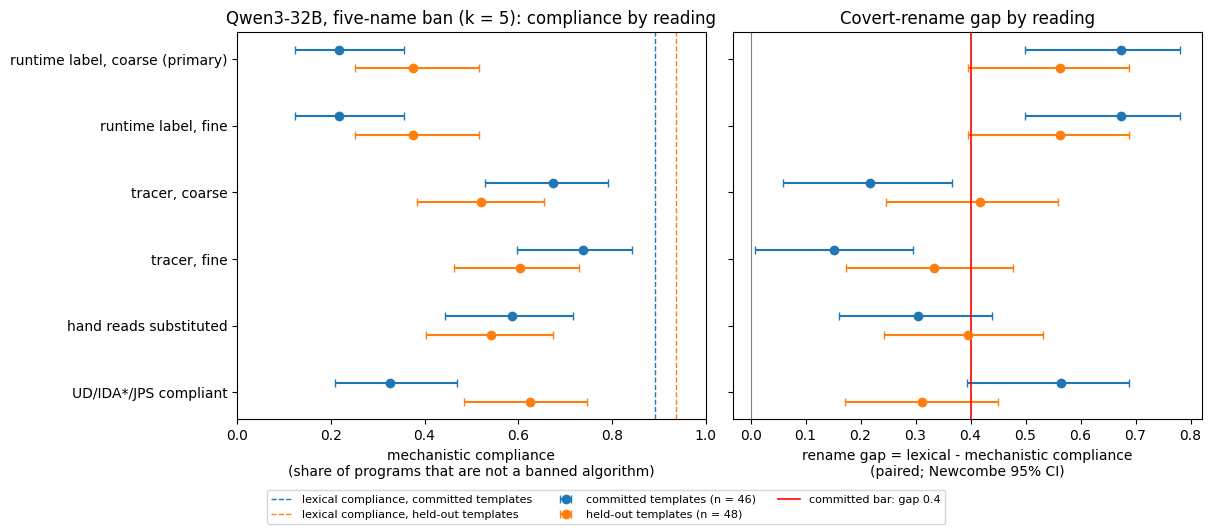

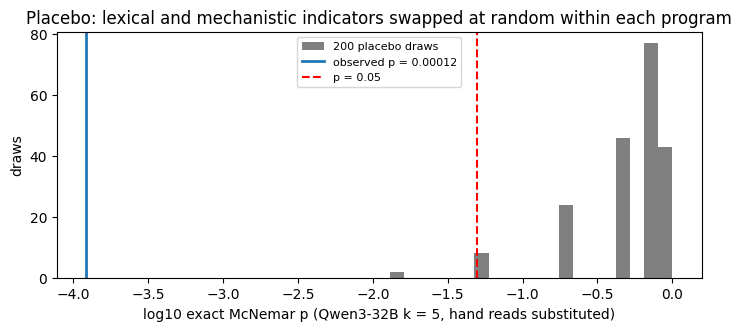

In [18]:
# 1) the readings in one picture: mechanistic compliance (Wilson 95%) and the paired rename gap (Newcombe 95%)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True, layout="constrained")
ys = np.arange(len(READINGS))[::-1]
for kk, lab, col, dy in (("5", "committed templates", "tab:blue", 0.14),
                         ("ho", "held-out templates", "tab:orange", -0.14)):
    mech = np.array([c32[kk][rd]["mech"] for rd in READINGS])
    wil = np.array([c32[kk][rd]["mech_wilson"] for rd in READINGS])
    gap = np.array([c32[kk][rd]["gap"] for rd in READINGS])
    ci = np.array([c32[kk][rd]["ci"] for rd in READINGS])
    # error-bar lengths clipped at 0: a Wilson bound at a rate of 1 can sit 1e-16 below it
    ax1.errorbar(mech, ys + dy, xerr=np.clip([mech - wil[:, 0], wil[:, 1] - mech], 0, None), fmt="o", color=col,
                 capsize=3, label=f"{lab} (n = {c32[kk]['runtime_coarse']['n']})")
    ax1.axvline(c32[kk]["runtime_coarse"]["lex"], color=col, ls="--", lw=1, label=f"lexical compliance, {lab}")
    ax2.errorbar(gap, ys + dy, xerr=np.clip([gap - ci[:, 0], ci[:, 1] - gap], 0, None), fmt="o", color=col,
                 capsize=3)
ax1.set_yticks(ys, [READING_LABEL[rd] for rd in READINGS])
ax1.set_xlabel("mechanistic compliance\n(share of programs that are not a banned algorithm)")
ax1.set_xlim(0, 1)
ax1.set_title("Qwen3-32B, five-name ban (k = 5): compliance by reading")
ax2.axvline(0.4, color="red", lw=1.2, label="committed bar: gap 0.4")
ax2.axvline(0, color="grey", lw=0.8)
ax2.set_xlabel("rename gap = lexical - mechanistic compliance\n(paired; Newcombe 95% CI)")
ax2.set_title("Covert-rename gap by reading")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="outside lower center", ncol=3, fontsize=8)
plt.show()

# 2) the McNemar placebo: random within-program swaps must stop the test from rejecting
fig, ax = plt.subplots(figsize=(7, 3.2), layout="constrained")
ax.hist(np.log10(spot["placebo_p"]), bins=20, color="grey", label=f"{spot['placebo']['draws']} placebo draws")
ax.axvline(np.log10(spot["placebo"]["observed_p"]), color="tab:blue", lw=2,
           label=f"observed p = {spot['placebo']['observed_p']:.2g}")
ax.axvline(np.log10(0.05), color="red", ls="--", label="p = 0.05")
ax.set_xlabel("log10 exact McNemar p (Qwen3-32B k = 5, hand reads substituted)")
ax.set_ylabel("draws")
ax.set_title("Placebo: lexical and mechanistic indicators swapped at random within each program")
ax.legend(fontsize=8)
plt.show()